# 🟠 Tarefa 2

* Disciplina: Física com Python 1 (2026.2) — CBPF
* Autor: Luiz Guilherme Ataliba dos Reis
* Obs: Código desenvolvido para fins de avaliação acadêmica. Disponibilizado publicamente sob a Licença MIT para consulta educacional.

## 🔶 Q1

Para entender o Método de Monte Carlo (MMC), *reproduza* os exemplos deste [tutorial](https://youtu.be/vNWTRsBFmUw?si=5_bsqCWXVeXh4CUx).

* Aprimore a análise de convergência usando gráficos de [boxplots concatenados lado a lado](https://youtu.be/BFpbchNlIeg?si=M-rxC7cUXAyniQZ8) para diferentes tamanhos de amostras.

> Em todos os casos, adicione comentários com uma discussão que explique os gráficos gerados.

In [118]:
import random
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binom, norm, skew, kurtosis

plt.rcParams["text.usetex"] = True

In [6]:
def pi_monteCarlo(N,plot=False,verbose=True):
    if plot:
        fig, ax = plt.subplots()
        fig.set_size_inches(4,4)
        circle=plt.Circle((0,0),1,color='lightblue')
        square=plt.Rectangle((-1,-1),2,2,color='red',alpha=0.7)
        ax.add_patch(square)
        ax.add_patch(circle)

    
    N_in=0 
    cont=0

    #Simulacao
    while(cont<N): 
        x=2*random.random()-1 
        y=2*random.random()-1 
        z=x**2+y**2 

        if(z<=1): 
            N_in+=1
            if plot:
                ax.plot(x,y,'o',color='blue')
        else:
            if plot:
                ax.plot(x,y,'o',color='pink')
        cont+=1

    #Valor simulado de pi
    pi_mc=4*N_in/N

    if verbose:
        print('Numero de pontos dentro: ',N_in)
        print('Numero de pontos fora: ',N-N_in)
        print('Valor simulado de pi: ',pi_mc)
        print('Valor de pi: ',math.pi)
        print('Erro: ',pi_mc-math.pi)
        print('Precisao: ',100*(1-abs(pi_mc-math.pi)/math.pi),'%')
        print('Quantidade de iteracoes: ',cont)

    if plot:
        plt.show()

Numero de pontos dentro:  80
Numero de pontos fora:  20
Valor simulado de pi:  3.2
Valor de pi:  3.141592653589793
Erro:  0.05840734641020706
Precisao:  98.14083642118698 %
Quantidade de iteracoes:  100


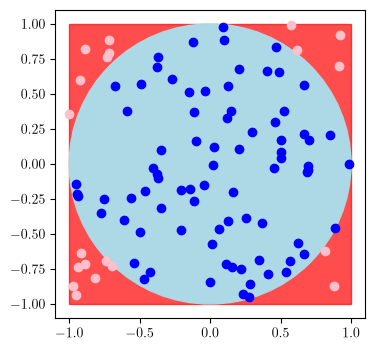

In [7]:
pi_monteCarlo(N=100,plot=True)

Numero de pontos dentro:  772
Numero de pontos fora:  228
Valor simulado de pi:  3.088
Valor de pi:  3.141592653589793
Erro:  -0.05359265358979304
Precisao:  98.29409285355457 %
Quantidade de iteracoes:  1000


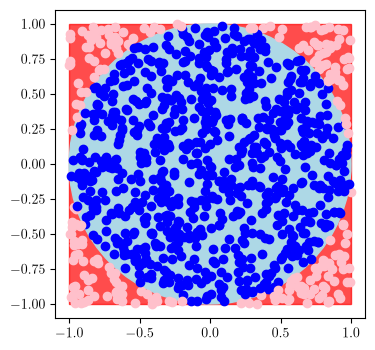

In [8]:
pi_monteCarlo(N=1000,plot=True)

Vazendo várias simulações para um mesmo valor de $N$, conseguimos obter diferentes valores estimados de $\pi$, de acordo com o processo aleatório. Assim, o gráfico à seguir mostra como esses valores estimados de $\pi$ variam para diferentes valores de $N$.  

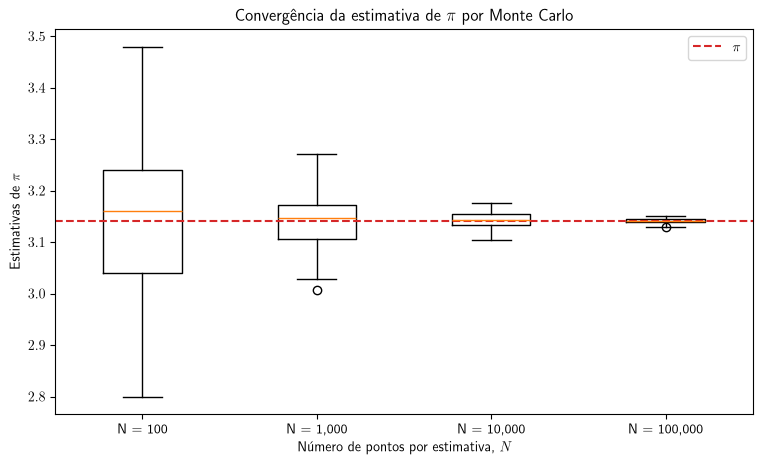

In [9]:
N_values = [100, 1_000, 10_000, 100_000]
n_repetitions = 100
pi_samples = []

for N in N_values:
    estimates = []

    for _ in range(n_repetitions):
        N_in = 0
        cont = 0

        while cont < N:
            x = 2 * random.random() - 1
            y = 2 * random.random() - 1
            z = x**2 + y**2

            if z <= 1:
                N_in += 1

            cont += 1

        estimates.append(4 * N_in / N)

    pi_samples.append(estimates)

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(pi_samples, tick_labels=[f"N = {N:,}" for N in N_values])
ax.axhline(math.pi, color="tab:red", linestyle="--", label=r"$\pi$")
ax.set_title(r"Convergência da estimativa de $\pi$ por Monte Carlo")
ax.set_xlabel(r"Número de pontos por estimativa, $N$")
ax.set_ylabel(r"Estimativas de $\pi$")
ax.legend()
plt.show()

# Os boxplots ficam mais estreitas para N maiores, indicando menor dispersão das estimativas.

### 🔹 Estimativa de π por Monte Carlo

* (a) Reobtenha os resultados mostrados na Fig. 1 do artigo de [Strbac-Savic, Miletic e Stefanović (2015)](https://www.researchgate.net/profile/Ana-Miletic-2/publication/282909462_The_estimation_of_Pi_using_Monte_Carlo_technique_with_interactive_animations/links/56b34b8008ae3d06a2664232/The-estimation-of-Pi-using-Monte-Carlo-technique-with-interactive-animations.pdf). Para auxiliar, use o Matplotlib. Coloque no título de cada painel o valor da estimativa de π.
* (b) Faça uma organização tabular dos resultados anteriores similar à Tabela 1 do artigo de [Sharma, Singhal e Agrawal (2021)](https://iopscience.iop.org/article/10.1088/1757-899X/1116/1/012130/meta). Para auxiliar, use o Pandas.

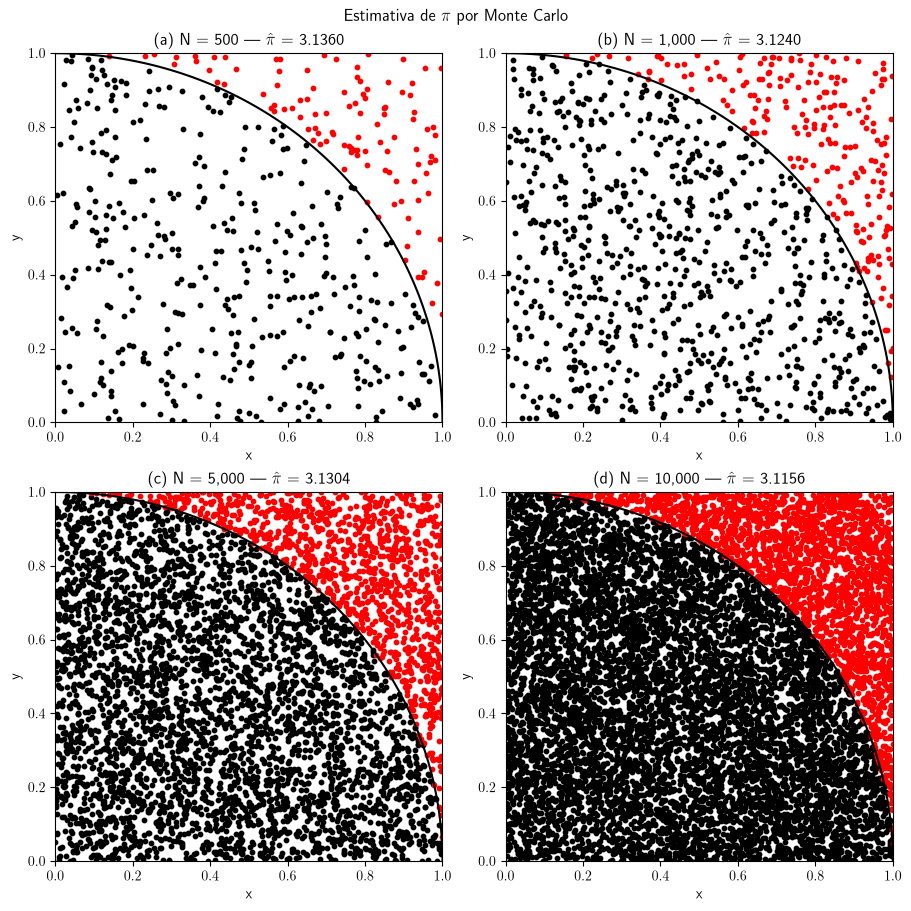

In [29]:
rng = np.random.default_rng(42)
Ns = [500, 1000, 5000, 10000]
dados = []

fig, axes = plt.subplots(2, 2, figsize=(9, 9), constrained_layout=True)

for ax, N, letra in zip(axes.flat, Ns, "abcd"):
    x = rng.random(N)
    y = rng.random(N)

    dentro = x**2 + y**2 <= 1
    M = dentro.sum()
    pi_hat = 4 * M / N
    dados.append((N, M, pi_hat))

    theta = np.linspace(0, np.pi / 2, 100)

    ax.scatter(x[dentro], y[dentro], c="black", s=10)
    ax.scatter(x[~dentro], y[~dentro], c="red", s=10)
    ax.plot(np.cos(theta), np.sin(theta), c="black")

    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="x", ylabel="y")
    ax.set_title(f"({letra}) N = {N:,}  |  $\\hat{{\\pi}}$ = {pi_hat:.4f}")

fig.suptitle("Estimativa de $\\pi$ por Monte Carlo")
plt.show()

In [30]:
tabela = pd.DataFrame({
    "N Iterações": [N for N, M, pi_hat in dados],
    "Pontos Dentro": [M for N, M, pi_hat in dados],
    "Valor de Pi": [round(pi_hat, 4) for N, M, pi_hat in dados],
    "Erro Absoluto": [round(abs(pi_hat - math.pi), 4) for N, M, pi_hat in dados],
    "%Error": [round(100 * abs(pi_hat - math.pi) / math.pi, 4) for N, M, pi_hat in dados],
})
tabela


,N Iterações,Pontos Dentro,Valor de Pi,Erro Absoluto,%Error
0,500,392,3.1360,0.0056,0.1780
1,1000,781,3.1240,0.0176,0.5600
2,5000,3913,3.1304,0.0112,0.3563
3,10000,7789,3.1156,0.0260,0.8274


> **Opcional:** quem quiser se aprofundar pode consultar este [tutorial de nível intermediário](https://youtu.be/rNOe62Z3zZg?si=KiNHd7sLJo5GczrW).

## 🔶 Q2

Primeiramente, reproduza o código do vídeo [Método de Monte Carlo, passeio aleatório e difusão](https://youtu.be/Rj9_fPLSMyc?si=K6P0JL9dJ6UOjv0f) no seu Colab, com os correspondentes gráficos relacionados ao passeio aleatório.

Em seguida, adapte o código para obter:

* A distribuição de probabilidade $P(x, t)$ para $t = 5$, comparando-a com a distribuição binomial; e para $t = 500$, comparando-a com a distribuição gaussiana. Discuta o **Teorema Central do Limite (TCL)** em um painel 1×2.
* A evolução temporal da média, variância, assimetria e curtose. Faça um painel 1×3 usando [plt.subplots(1, 3)](https://education.molssi.org/python-visualization/matplotlib/subplots.html). Considere $t$ de 0 até $10^3$ e $M$ trajetórias, com $M = \{10, 10^2, 10^3\}$, e discuta a **Lei dos Grandes Números (LGN)**.

Em todos os casos, adicione gráficos e faça a discussão com base na [Física da difusão](https://youtu.be/BLRH48ulbUQ?si=qyf0l6GbBIRTbt2U).

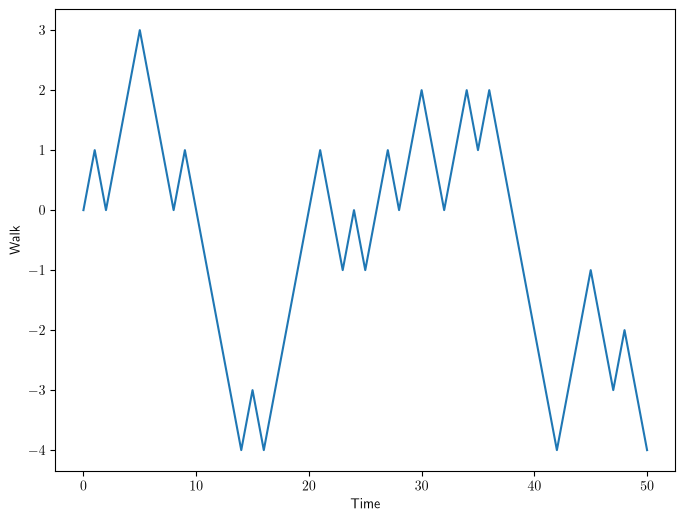

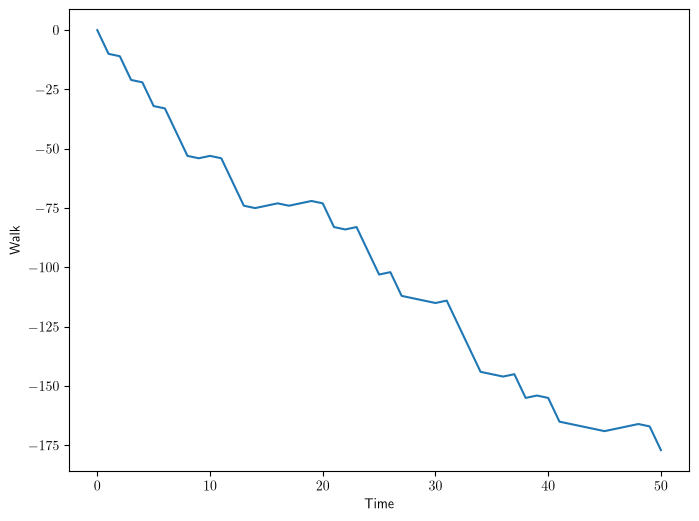

In [ ]:
def randomWalk(x, time):
    Ts = [0]
    X = [0]
    for t in range(1, time+1):
        Ts.append(t)
        rand = random.choice(x)
        step = X[t-1] + rand
        X.append(step)
    plt.figure(figsize = (8,6))
    plt.plot(Ts, X, label='Random walk')
    plt.xlabel('Time')
    plt.ylabel('Walk')
    plt.show()

randomWalk([-1,1], 50)
randomWalk([-1, 1, -10], 50)

In [ ]:
rng = np.random.default_rng(42)
t_max = 1000
M_max = 10000

# Vamos ter uma matriz onde linha é a trajetória e cada coluna é um instante t
steps = rng.integers(0, 2, size=(M_max, t_max)) # Sorteia de 0 a 1 - matrix (M_max, t_max)
steps = steps * 2 - 1 # transformando de -1 a 1

trajectories = np.cumsum(steps, axis=1)
# A soma cumulativa transforma os steps em posições
# steps = [[+1, +1, -1],
#          [-1, +1, +1]]
#              
# steps = [[ 1,  2,  1],
#          [-1,  0,  1]]

# Vamos adicionar uma coluna com as posições iniciais (todos x_0=0 em t=0)
pos = np.concatenate((np.zeros((M_max, 1)), trajectories), axis=1)

array([[  0.,  -1.,   0., ...,  16.,  17.,  18.],
       [  0.,   1.,   2., ..., -12., -13., -14.],
       [  0.,   1.,   0., ..., -16., -17., -16.],
       ...,
       [  0.,   1.,   0., ..., -52., -53., -54.],
       [  0.,   1.,   0., ...,   2.,   1.,   2.],
       [  0.,   1.,   0., ...,  56.,  57.,  58.]], shape=(10000, 1001))

**Cola das relações da matrix de posições**

pos[i, t] = posição do caminhante i no instante t

pos[i, :] = uma trajetória completa do caminhante i

pos[:, t] = a distribuição das posições em t 

### Lógica para encontrar a distribuição
Se o número de passos para a direita é m, podemos escrever a posição final como
    $$X_t = m - (t-m) = 2m - t$$
onde $(t-m)$ é a quantidade de passos para a esquerda

Então a quantidade de passos para a direita é
    $$m = \frac{X_t + t}{2}$$

In [70]:
def calculate_dist(t, pos):
    # Todos os estados finais possívels para uma caminhada de t passos
    k = np.arange(-t, t + 1, 2)

    # Contando quantas vezes cada uma das k condições finais ocorreram na simulação
    contagens = np.array([(pos[:, t] == valor).sum() for valor in k])

    # Calculando a probabilidade de cada um dos finais possíveis, em t passos
    probabilidades = binom.pmf(
        (k + t) // 2,  # Número de passos para a direita para atingir a posição final k
        t,             # Número de passos
        0.5            # Probabilidade de se mover para a direita
    )

    return k, contagens, probabilidades
    

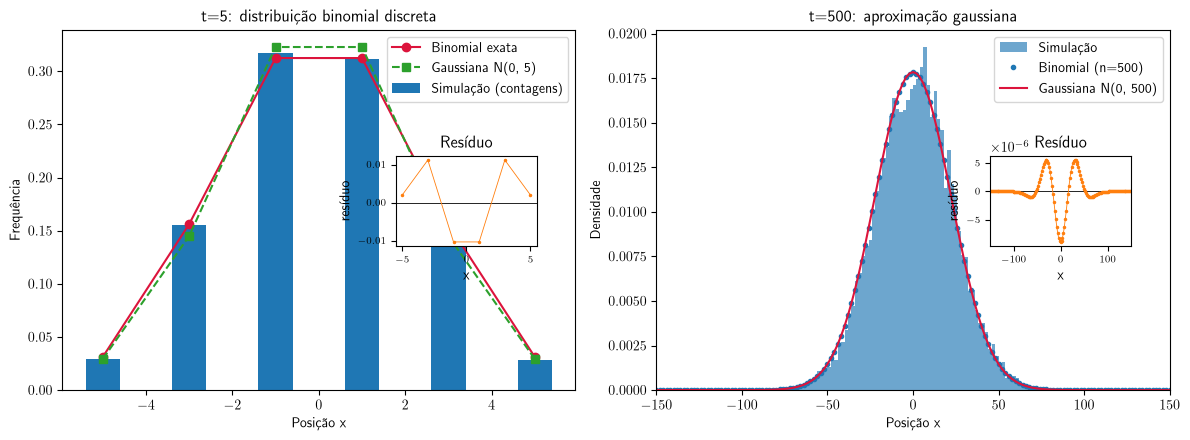

In [112]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

t = 5
k, contagens, probabilidades = calculate_dist(t, pos)

axes[0].bar(k, contagens / M_max, width=0.8, label="Simulação (contagens)")
axes[0].plot(k, probabilidades , "o-", color="crimson", label="Binomial exata")
axes[0].plot(k, 2 * norm.pdf(k, loc=0, scale=np.sqrt(t)),
             "s--", color="tab:green", label=f"Gaussiana N(0, {t})") # Distribuição gaussiana

axes[0].set(title="t=5: distribuição binomial discreta", xlabel="Posição x", ylabel="Frequência")
axes[0].legend()

residuo = probabilidades - 2 * norm.pdf(k, loc=0, scale=np.sqrt(t))  
axins = axes[0].inset_axes([0.65, 0.4, 0.275, 0.25])
axins.axhline(0, color="black", linewidth=0.6)
axins.plot(k, residuo, ".-", ms=3, linewidth=0.6, color="tab:orange")
axins.set(title=r"Resíduo", xlabel="x", ylabel="resíduo")
axins.tick_params(labelsize=7)


t = 500
k, contagens, probabilidades = calculate_dist(t, pos)

axes[1].hist(pos[:, t], bins=k, density=True, alpha=0.65, label="Simulação") # plotando distribuição em t
axes[1].plot(k, probabilidades / 2, "o", ms=3, color="tab:blue", label="Binomial (n=500)") # distribuição binomial (comparação)
axes[1].plot(k, norm.pdf(k, loc=0, scale=np.sqrt(t)), color="crimson", label="Gaussiana N(0, 500)") # Distribuição gaussiana

axes[1].set(title="t=500: aproximação gaussiana", xlabel="Posição x", ylabel="Densidade", xlim=(-150, 150))
axes[1].legend()

# Resíduo
residuo = probabilidades / 2 - norm.pdf(k, loc=0, scale=np.sqrt(t))  
axins = axes[1].inset_axes([0.65, 0.4, 0.275, 0.25])
axins.axhline(0, color="black", linewidth=0.6)
axins.plot(k, residuo, ".-", ms=3, linewidth=0.6, color="tab:orange")
axins.set(title=r"Resíduo", xlabel="x", ylabel="resíduo", xlim=(-150, 150))
axins.tick_params(labelsize=7)

fig.tight_layout()
plt.show()

### Interpretação
Para $t=5$ podemos notar que a distribuição simulada bate perfeitamente com uma binomial, porém não é exatamente uma gaussiana, o erro está na ordem de $10^{-2}$. Agora, quando aumentamos o número total de passos simulados, a distribuição é aproximadamente uma gaussiana, o que é ressaltado no resíduo que agora é da ordem de $10^{-6}$. 

Esse comportamento é explicado pelo **teorema central do limite** (TCL), uma vez que o passeio aleatório respeita as condições do TCL:
- os passos são independentes entre si;
- tem média e variância bem definida;

Ele deve convergir para uma distribuição gaussiana quando $t \to \infty$. 

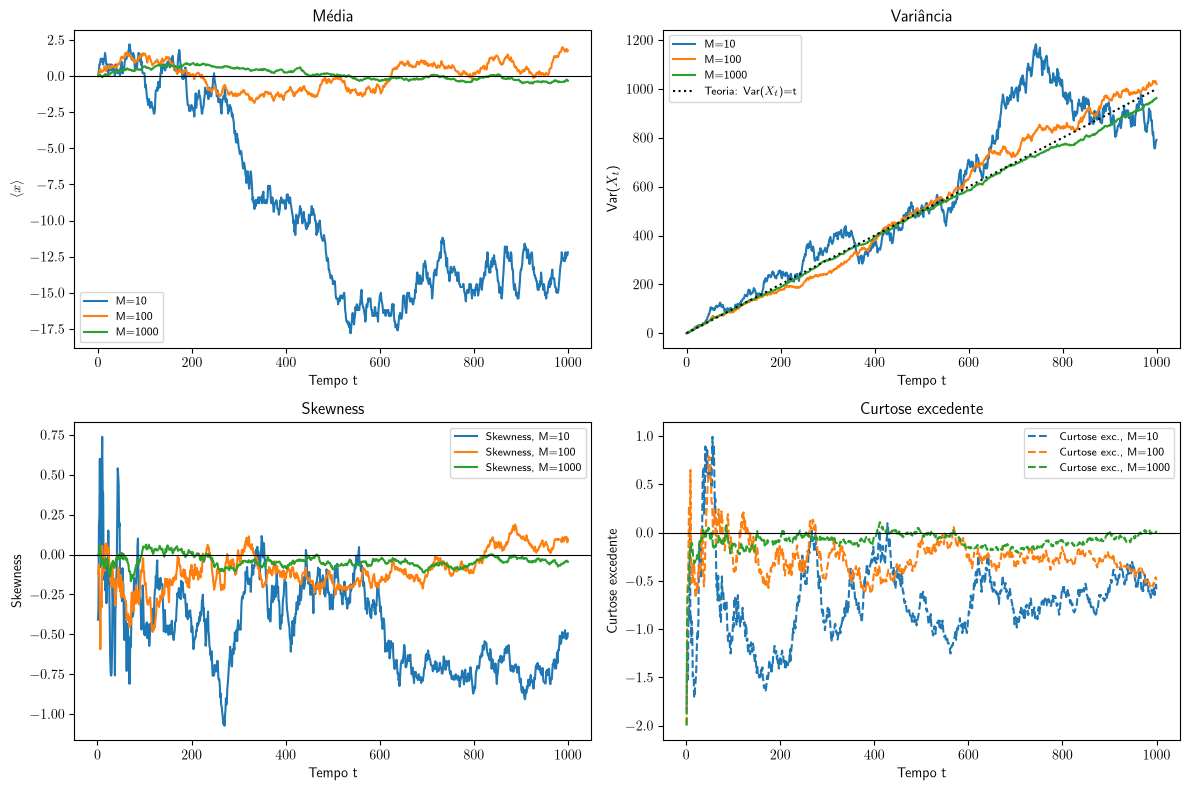

In [130]:
M_list = [10, 100, 1000]
tempos = np.arange(t_max + 1)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for M in M_list:
    trajetorias = pos[:M, :]
    medias = trajetorias.mean(axis=0)
    variancias = trajetorias.var(axis=0, ddof=0)
    skewness = skew(trajetorias, axis=0, bias=True)
    curtose = kurtosis(trajetorias, axis=0, fisher=True, bias=True)

    axes[0].plot(tempos, medias, label=f"M={M}")
    axes[1].plot(tempos, variancias, label=f"M={M}")
    axes[2].plot(tempos, skewness, label=f"Skewness, M={M}")
    axes[3].plot(tempos, curtose, linestyle="--", label=f"Curtose exc., M={M}")

axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(title="Média", xlabel="Tempo t", ylabel=r"$\langle x\rangle$")
axes[1].plot(tempos, tempos, color="black", linestyle=":", label=r"Teoria: Var($X_t$)=t")
axes[1].set(title="Variância", xlabel="Tempo t", ylabel=r"Var($X_t$)")
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set(title="Skewness", xlabel="Tempo t", ylabel="Skewness")
axes[3].axhline(0, color="black", linewidth=0.8)
axes[3].set(title="Curtose excedente", xlabel="Tempo t", ylabel="Curtose excedente")

for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


### Interpretação

Para o passeio aleatório clássico, os valores dos momentos são conhecidos:
- **Média**: $\langle X_t\rangle = 0$
- **Variância**: $\text{Var}(X_t) = t$
- **Skewness**: $\gamma_1(t) = 0$
- **Kurtosis**: $\gamma_2(t) = \frac{-2}{t}$, ou seja, ela começa negativa e conforme o tempo aumenta se aproxima de zero

Nos gráficos acima é direto notar que conforme aumenta-se a quantidade de amostras/simulações ($M$), os momentos cada vez mais se aproximam do valor teórico, apresentando menor flutuação. Isso é descrito pela lei dos grandes números, que nos diz que a medida que aumenta-se o número de observações independentes, a média amostral converge para o valor esperado da distribuição, que é o comportamento observado em todos os casos

Vale ainda notar que os comportamentos observados para pequenos valores de $M$, em especial $M=10$ são um artefato da simulação com poucas observações, uma vez que nesse caso poucas curvas podem tendenciar a simulação, como é o que aconteceu nos casos acima. 